the distribution of exercise ratings based off equipment 

In [1]:
# import the data from kagglehub 
import kagglehub
dir(kagglehub)
path= kagglehub.dataset_download('niharika41298/gym-exercise-data')
print('Path to dataset:',path)
import pandas as pd
import os 
folder_path=r"C:/Users/ahliy/Downloads/archive (5)/megaGymDataset.csv"
print(os.path.exists(folder_path))
print(os.listdir(os.path.dirname(folder_path)))
file_name='megaGymdDataset.csv'
file_path=os.path.join(folder_path)
df=pd.read_csv(file_path)

c:\Users\ahliy\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Path to dataset: C:\Users\ahliy\.cache\kagglehub\datasets\niharika41298\gym-exercise-data\versions\1
True
['megaGymDataset.csv']


In [2]:
# observe the data to determine what needs to be cleaned 
print(df.head())
print(df.tail)
print(df.info())
print(df.describe())

   Unnamed: 0                         Title  \
0           0        Partner plank band row   
1           1  Banded crunch isometric hold   
2           2         FYR Banded Plank Jack   
3           3                 Banded crunch   
4           4                        Crunch   

                                                Desc      Type    BodyPart  \
0  The partner plank band row is an abdominal exe...  Strength  Abdominals   
1  The banded crunch isometric hold is an exercis...  Strength  Abdominals   
2  The banded plank jack is a variation on the pl...  Strength  Abdominals   
3  The banded crunch is an exercise targeting the...  Strength  Abdominals   
4  The crunch is a popular core exercise targetin...  Strength  Abdominals   

  Equipment         Level  Rating RatingDesc  
0     Bands  Intermediate     0.0        NaN  
1     Bands  Intermediate     NaN        NaN  
2     Bands  Intermediate     NaN        NaN  
3     Bands  Intermediate     NaN        NaN  
4     Bands  

In [3]:
# clean data by removing duplicates, standarizing column names and handle missing values then save the cleaned data 
dir(df)
df.isna().sum()
df.dropna()
df.fillna(0)
df = df.ffill()
df.columns=(
    df.columns
    .str.lower()
    .str.strip()
    .str.replace(" ", "_")
)
df.isna().any()
print(df.columns)
df.isna().sum()
df = df.loc[:, ~df.columns.str.contains('^unnamed', case=False)]
print(df.columns)
df.dtypes
df.duplicated().sum()
df.to_csv('cleaned_gymdata.csv',index=False)

Index(['unnamed:_0', 'title', 'desc', 'type', 'bodypart', 'equipment', 'level',
       'rating', 'ratingdesc'],
      dtype='object')
Index(['title', 'desc', 'type', 'bodypart', 'equipment', 'level', 'rating',
       'ratingdesc'],
      dtype='object')


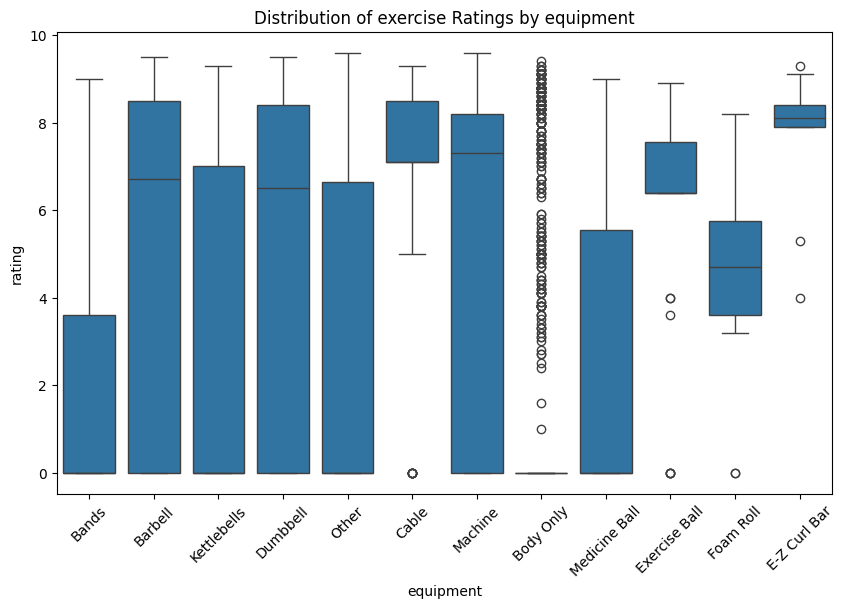

In [ ]:
# create a visualization of the cleaned data using a boxplot 
import matplotlib.pyplot as plt
import seaborn as sns
plt.figure(figsize=(10,6))
sns.boxplot(x='equipment',y='rating',data=df)
plt.title('Distribution of exercise Ratings by equipment')
plt.xlabel=('equipment')
plt.ylabel=('rating')
plt.xticks(rotation=45)
plt.show()

after cleaning the data, i used a boxplot to highlight the variability of ratings based off equipment. Bodyweight excerices are comparable to equipment based exercies as shown here.